# 06 — Final CatBoost Hyperparameter Optimization and Probability Calibration

The data pipeline, pre-fight feature engineering and Elo system are now frozen.

This notebook performs the last model-development stage before opening the untouched final test set.

The objectives are:

1. Optimize the **CatBoost hyperparameters** using chronological validation only.
2. Select the final configuration using mean Log Loss and temporal robustness.
3. Freeze the final boosting iteration count.
4. Review the quality of the predicted probabilities.
5. Compare:
   - uncalibrated probabilities,
   - Platt scaling,
   - isotonic regression.
6. Freeze the calibration decision.
7. Save all model-development artifacts required for the final test.

The final 15% test period remains completely untouched by default.

The primary metric is **Log Loss**. Brier score, ROC AUC, accuracy and Expected Calibration Error (ECE) are used as secondary diagnostics.

## Methodology

I deliberately separate model tuning from probability calibration.

The complete chronological dataset is divided conceptually into:

```text
0% -------------------------------------------------------------- 100%

|<------------- model development ------------->|<-- final test -->|
0%                                              85%                100%

|<-- hyperparameter search -->|<-- calibration development -->|
0%                           70%                         85%

                              | calibration fit | calibration eval |
                              70%             77.5%               85%
```

### Hyperparameter optimization

The first 70% of the dataset is used for expanding-window temporal validation.

Three folds are used:

```text
Fold 1: train 0–40%  → validate 40–50%
Fold 2: train 0–50%  → validate 50–60%
Fold 3: train 0–60%  → validate 60–70%
```

A configuration is therefore rewarded for working across multiple UFC periods rather than only one validation window.

### Calibration

After hyperparameters are frozen:

- the base model is trained on the first 70%;
- calibration methods are fitted on 70–77.5%;
- they are evaluated on 77.5–85%.

This prevents the calibration method from being selected using the final test set.

### Final test

The last 15% is not used anywhere in this notebook unless I explicitly change:

```python
RUN_FINAL_TEST = True
```

I should only do that after accepting both the hyperparameters and the calibration decision.

In [2]:
from __future__ import annotations

from dataclasses import dataclass
import json
import math
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)
from sklearn.model_selection import ParameterSampler

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 220)


## Project paths and final-development settings

The search budget is intentionally larger than in the Elo-development notebooks because this is the final CatBoost tuning stage.

The final test remains disabled.

In [3]:
def find_project_root() -> Path:
    starts = [Path.cwd(), Path.cwd().parent]

    for start in starts:
        for path in [start, *start.parents]:
            if (path / "src").exists() and (path / "data").exists():
                return path

    raise FileNotFoundError(
        "Could not locate the UFC_PREDICTOR project root."
    )


PROJECT_ROOT = find_project_root()

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "ufcstats"
RESULTS_DIR = PROJECT_ROOT / "reports" / "final_model_optimization"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DATASET_PATH = PROCESSED_DIR / "fight_dataset.parquet"
DATASET_REPORT_PATH = PROCESSED_DIR / "fight_dataset_report.json"
SANITY_REPORT_PATH = PROCESSED_DIR / "pipeline_sanity_report.json"

RUN_FINAL_TEST = False

N_HYPERPARAMETER_CANDIDATES = 40
EARLY_STOPPING_ROUNDS = 120
MAX_SEARCH_ITERATIONS = 2000

MIN_CALIBRATION_LOGLOSS_GAIN = 0.0005
MIN_CALIBRATION_BOOTSTRAP_PROBABILITY = 0.80
CALIBRATION_BOOTSTRAP_SAMPLES = 2000

print("Project root:", PROJECT_ROOT)
print("Results directory:", RESULTS_DIR)
print("Hyperparameter candidates:", N_HYPERPARAMETER_CANDIDATES)
print("Final test enabled:", RUN_FINAL_TEST)


Project root: c:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR
Results directory: c:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR\reports\final_model_optimization
Hyperparameter candidates: 40
Final test enabled: False


## Load the frozen production dataset

I use the production `fight_dataset.parquet` generated after freezing the final Elo system.

The notebook checks that no Effective Elo or decay feature has re-entered the model feature manifest.

In [4]:
required_paths = [
    DATASET_PATH,
    DATASET_REPORT_PATH,
]

missing = [path for path in required_paths if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Required files are missing:\n"
        + "\n".join(f"  - {path}" for path in missing)
    )

df = pd.read_parquet(DATASET_PATH)

with DATASET_REPORT_PATH.open("r", encoding="utf-8") as f:
    dataset_report = json.load(f)

df["event_date"] = pd.to_datetime(df["event_date"])

df = (
    df.sort_values(
        ["event_date", "event_id", "fight_order"],
        ascending=[True, True, False],
        kind="stable",
    )
    .reset_index(drop=True)
)

manifest = dataset_report["feature_manifest"]

numeric_features = [
    col
    for col in manifest["numeric_model_features"]
    if col in df.columns
]

categorical_features = [
    col
    for col in manifest["categorical_model_features"]
    if col in df.columns
]

model_features = list(dict.fromkeys(
    numeric_features + categorical_features
))

forbidden_feature_tokens = (
    "effective",
    "elo_decay_fraction",
)

forbidden_features = [
    col
    for col in model_features
    if any(token in col for token in forbidden_feature_tokens)
]

if forbidden_features:
    raise ValueError(
        "Frozen production dataset contains forbidden Effective/decay Elo features:\n"
        + "\n".join(forbidden_features)
    )

if df["fight_id"].duplicated().any():
    raise ValueError("fight_dataset.parquet contains duplicate fight_id values.")

if not df["target"].dropna().isin([0, 1]).all():
    raise ValueError("Target contains values outside {0, 1}.")

print(f"Rows: {len(df):,}")
print(f"Model features: {len(model_features):,}")
print(f"Numeric features: {len(numeric_features):,}")
print(f"Categorical features: {len(categorical_features):,}")
print(
    "Date range:",
    df["event_date"].min().date(),
    "->",
    df["event_date"].max().date(),
)
print(f"Target rate: {df['target'].mean():.4f}")
print("Frozen Raw-Elo feature check passed.")


Rows: 8,731
Model features: 145
Numeric features: 140
Categorical features: 5
Date range: 1994-03-11 -> 2026-09-12
Target rate: 0.5004
Frozen Raw-Elo feature check passed.


## Optional pipeline sanity report check

If `pipeline_sanity_report.json` exists, I verify that the production sanity suite finished with zero failures before tuning the model.

In [5]:
if SANITY_REPORT_PATH.exists():
    with SANITY_REPORT_PATH.open("r", encoding="utf-8") as f:
        sanity_report = json.load(f)

    # The report format may contain either a top-level summary or individual checks.
    summary = sanity_report.get("summary", sanity_report)

    fail_count = summary.get(
        "fail",
        summary.get(
            "FAIL",
            summary.get("failed_checks", 0),
        ),
    )

    if isinstance(fail_count, list):
        fail_count = len(fail_count)

    if int(fail_count) != 0:
        raise ValueError(
            "The production pipeline sanity report contains failures. "
            "Fix them before tuning the final model."
        )

    print("Pipeline sanity report found: zero failures.")
else:
    print(
        "Sanity report not found. "
        "The dataset checks above passed, but I recommend running "
        "`python -m src.features.sanity_check_pipeline` first."
    )


Pipeline sanity report found: zero failures.


# Chronological development split

I keep the final 15% completely untouched.

The first 70% is used for hyperparameter optimization.

The 70–85% interval is reserved exclusively for probability-calibration development.

In [6]:
n = len(df)

search_end = int(n * 0.70)
calibration_fit_end = int(n * 0.775)
development_end = int(n * 0.85)

search_idx = np.arange(0, search_end)
calibration_fit_idx = np.arange(
    search_end,
    calibration_fit_end,
)
calibration_eval_idx = np.arange(
    calibration_fit_end,
    development_end,
)
test_idx = np.arange(
    development_end,
    n,
)

split_summary = pd.DataFrame([
    {
        "split": "hyperparameter_search",
        "rows": len(search_idx),
        "date_min": df.iloc[search_idx]["event_date"].min(),
        "date_max": df.iloc[search_idx]["event_date"].max(),
        "target_rate": df.iloc[search_idx]["target"].mean(),
    },
    {
        "split": "calibration_fit",
        "rows": len(calibration_fit_idx),
        "date_min": df.iloc[calibration_fit_idx]["event_date"].min(),
        "date_max": df.iloc[calibration_fit_idx]["event_date"].max(),
        "target_rate": df.iloc[calibration_fit_idx]["target"].mean(),
    },
    {
        "split": "calibration_eval",
        "rows": len(calibration_eval_idx),
        "date_min": df.iloc[calibration_eval_idx]["event_date"].min(),
        "date_max": df.iloc[calibration_eval_idx]["event_date"].max(),
        "target_rate": df.iloc[calibration_eval_idx]["target"].mean(),
    },
    {
        "split": "FINAL_TEST_UNTOUCHED",
        "rows": len(test_idx),
        "date_min": df.iloc[test_idx]["event_date"].min(),
        "date_max": df.iloc[test_idx]["event_date"].max(),
        "target_rate": df.iloc[test_idx]["target"].mean(),
    },
])

display(split_summary)


,split,rows,date_min,date_max,target_rate
0,hyperparameter_search,6111,1994-03-11,2021-08-07,0.507937
1,calibration_fit,655,2021-08-07,2022-11-19,0.487023
2,calibration_eval,655,2022-11-19,2024-03-16,0.491603
3,FINAL_TEST_UNTOUCHED,1310,2024-03-16,2026-09-12,0.476336


## Expanding-window folds for hyperparameter search

All folds remain entirely before the calibration-development period.

In [7]:
folds = [
    {
        "name": "fold_1",
        "train_idx": np.arange(0, int(n * 0.40)),
        "validation_idx": np.arange(
            int(n * 0.40),
            int(n * 0.50),
        ),
    },
    {
        "name": "fold_2",
        "train_idx": np.arange(0, int(n * 0.50)),
        "validation_idx": np.arange(
            int(n * 0.50),
            int(n * 0.60),
        ),
    },
    {
        "name": "fold_3",
        "train_idx": np.arange(0, int(n * 0.60)),
        "validation_idx": np.arange(
            int(n * 0.60),
            int(n * 0.70),
        ),
    },
]

fold_rows = []

for fold in folds:
    train_part = df.iloc[fold["train_idx"]]
    val_part = df.iloc[fold["validation_idx"]]

    fold_rows.append({
        "fold": fold["name"],
        "train_rows": len(train_part),
        "train_start": train_part["event_date"].min(),
        "train_end": train_part["event_date"].max(),
        "validation_rows": len(val_part),
        "validation_start": val_part["event_date"].min(),
        "validation_end": val_part["event_date"].max(),
    })

display(pd.DataFrame(fold_rows))


,fold,train_rows,train_start,train_end,validation_rows,validation_start,validation_end
0,fold_1,3492,1994-03-11,2016-01-30,873,2016-01-30,2017-12-09
1,fold_2,4365,1994-03-11,2017-12-09,873,2017-12-09,2019-09-28
2,fold_3,5238,1994-03-11,2019-09-28,873,2019-09-28,2021-08-07


# Evaluation helpers

Log Loss is the primary optimization objective.

Expected Calibration Error is calculated with equal-width probability bins and is used only as a diagnostic, not as the hyperparameter-search objective.

In [8]:
def expected_calibration_error(
    y_true: np.ndarray,
    probabilities: np.ndarray,
    n_bins: int = 10,
) -> float:
    y_true = np.asarray(y_true, dtype=float)
    probabilities = np.asarray(probabilities, dtype=float)

    edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(
        probabilities,
        edges[1:-1],
        right=True,
    )

    ece = 0.0

    for bin_id in range(n_bins):
        mask = bin_ids == bin_id

        if not mask.any():
            continue

        bin_confidence = probabilities[mask].mean()
        bin_accuracy = y_true[mask].mean()
        bin_weight = mask.mean()

        ece += bin_weight * abs(
            bin_accuracy - bin_confidence
        )

    return float(ece)


def evaluate_probabilities(
    y_true: pd.Series | np.ndarray,
    probabilities: np.ndarray,
) -> dict[str, float]:
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.clip(
        np.asarray(probabilities, dtype=float),
        1e-7,
        1 - 1e-7,
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    return {
        "log_loss": float(
            log_loss(y_true, probabilities)
        ),
        "brier": float(
            brier_score_loss(y_true, probabilities)
        ),
        "roc_auc": float(
            roc_auc_score(y_true, probabilities)
        ),
        "accuracy": float(
            accuracy_score(y_true, predictions)
        ),
        "ece_10": expected_calibration_error(
            y_true,
            probabilities,
            n_bins=10,
        ),
    }


def prepare_catboost_frame(
    frame: pd.DataFrame,
) -> pd.DataFrame:
    frame = frame[model_features].copy()

    for col in categorical_features:
        frame[col] = (
            frame[col]
            .astype("string")
            .fillna("Unknown")
            .astype(str)
        )

    return frame


X_all = prepare_catboost_frame(df)
y_all = df["target"].astype(int)


# Hyperparameter search space

I keep the model family fixed as standard symmetric-tree CatBoost.

I tune parameters that directly control model capacity, regularization and stochasticity:

- `depth`
- `learning_rate`
- `l2_leaf_reg`
- `random_strength`
- `bagging_temperature`
- `border_count`

The maximum number of boosting iterations is deliberately not optimized as an ordinary search parameter.

Instead, every fold uses early stopping and I later freeze the final iteration count from the selected configuration.

In [9]:
REFERENCE_PARAMS = {
    "depth": 6,
    "learning_rate": 0.03,
    "l2_leaf_reg": 5.0,
    "random_strength": 1.0,
    "bagging_temperature": 1.0,
    "border_count": 254,
}

PARAMETER_SPACE = {
    "depth": [4, 5, 6, 7, 8],
    "learning_rate": [
        0.015,
        0.02,
        0.03,
        0.04,
        0.05,
    ],
    "l2_leaf_reg": [
        3.0,
        5.0,
        7.0,
        10.0,
        15.0,
        20.0,
    ],
    "random_strength": [
        0.0,
        0.5,
        1.0,
        2.0,
    ],
    "bagging_temperature": [
        0.0,
        0.5,
        1.0,
        2.0,
        4.0,
    ],
    "border_count": [
        64,
        128,
        254,
    ],
}

sampled = list(ParameterSampler(
    PARAMETER_SPACE,
    n_iter=N_HYPERPARAMETER_CANDIDATES,
    random_state=RANDOM_SEED,
))

candidate_params = [
    {
        "candidate": "reference",
        **REFERENCE_PARAMS,
    }
]

seen = {
    tuple(sorted(REFERENCE_PARAMS.items()))
}

for i, params in enumerate(sampled, start=1):
    key = tuple(sorted(params.items()))

    if key in seen:
        continue

    seen.add(key)

    candidate_params.append({
        "candidate": f"search_{i:02d}",
        **params,
    })

print("Unique candidates:", len(candidate_params))
display(pd.DataFrame(candidate_params).head())


Unique candidates: 41


,candidate,depth,learning_rate,l2_leaf_reg,random_strength,bagging_temperature,border_count
0,reference,6,0.030,5.0,1.0,1.0,254
1,search_01,4,0.030,10.0,1.0,4.0,64
2,search_02,6,0.015,5.0,0.0,0.0,128
3,search_03,8,0.030,20.0,1.0,1.0,254
4,search_04,7,0.030,5.0,2.0,1.0,254


# Run the temporal hyperparameter search

Each configuration is trained independently on all three folds.

The final ranking prioritizes:

1. lowest **mean validation Log Loss**;
2. lowest **worst-fold Log Loss**;
3. lowest Log Loss standard deviation.

This prevents a configuration from winning because of one unusually favourable validation period.

In [10]:
BASE_CATBOOST_PARAMS = {
    "loss_function": "Logloss",
    "eval_metric": "Logloss",
    "iterations": MAX_SEARCH_ITERATIONS,
    "bootstrap_type": "Bayesian",
    "random_seed": RANDOM_SEED,
    "verbose": False,
    "allow_writing_files": False,
    "use_best_model": True,
    "thread_count": -1,
}

search_rows = []

for candidate_number, candidate in enumerate(
    candidate_params,
    start=1,
):
    candidate_name = candidate["candidate"]

    model_params = {
        **BASE_CATBOOST_PARAMS,
        **{
            key: value
            for key, value in candidate.items()
            if key != "candidate"
        },
    }

    print(
        f"[{candidate_number}/{len(candidate_params)}] "
        f"{candidate_name}"
    )

    for fold in folds:
        train_idx = fold["train_idx"]
        validation_idx = fold["validation_idx"]

        X_train = X_all.iloc[train_idx]
        X_validation = X_all.iloc[validation_idx]

        y_train = y_all.iloc[train_idx]
        y_validation = y_all.iloc[validation_idx]

        model = CatBoostClassifier(
            **model_params
        )

        model.fit(
            X_train,
            y_train,
            eval_set=(X_validation, y_validation),
            cat_features=categorical_features,
            early_stopping_rounds=EARLY_STOPPING_ROUNDS,
            verbose=False,
        )

        probabilities = model.predict_proba(
            X_validation
        )[:, 1]

        metrics = evaluate_probabilities(
            y_validation,
            probabilities,
        )

        best_iteration = int(
            model.get_best_iteration()
        )

        search_rows.append({
            "candidate": candidate_name,
            "fold": fold["name"],
            **{
                key: value
                for key, value in candidate.items()
                if key != "candidate"
            },
            **metrics,
            "best_iteration": best_iteration,
        })

search_results_df = pd.DataFrame(search_rows)

display(search_results_df.head())


[1/41] reference
[2/41] search_01
[3/41] search_02
[4/41] search_03
[5/41] search_04
[6/41] search_05
[7/41] search_06
[8/41] search_07
[9/41] search_08
[10/41] search_09
[11/41] search_10
[12/41] search_11
[13/41] search_12
[14/41] search_13
[15/41] search_14
[16/41] search_15
[17/41] search_16
[18/41] search_17
[19/41] search_18
[20/41] search_19
[21/41] search_20
[22/41] search_21
[23/41] search_22
[24/41] search_23
[25/41] search_24
[26/41] search_25
[27/41] search_26
[28/41] search_27
[29/41] search_28
[30/41] search_29
[31/41] search_30
[32/41] search_31
[33/41] search_32
[34/41] search_33
[35/41] search_34
[36/41] search_35
[37/41] search_36
[38/41] search_37
[39/41] search_38
[40/41] search_39
[41/41] search_40


,candidate,fold,depth,learning_rate,l2_leaf_reg,random_strength,bagging_temperature,border_count,log_loss,brier,roc_auc,accuracy,ece_10,best_iteration
0,reference,fold_1,6,0.03,5.0,1.0,1.0,254,0.627548,0.219996,0.696347,0.638030,0.042348,447
1,reference,fold_2,6,0.03,5.0,1.0,1.0,254,0.661682,0.234856,0.637438,0.600229,0.022135,229
2,reference,fold_3,6,0.03,5.0,1.0,1.0,254,0.662374,0.234756,0.645577,0.615120,0.024294,409
3,search_01,fold_1,4,0.03,10.0,1.0,4.0,64,0.625130,0.218888,0.700024,0.647194,0.052343,1817
4,search_01,fold_2,4,0.03,10.0,1.0,4.0,64,0.663415,0.235574,0.635080,0.589920,0.021739,411


In [11]:
search_summary_df = (
    search_results_df
    .groupby("candidate", as_index=False)
    .agg(
        mean_log_loss=("log_loss", "mean"),
        worst_log_loss=("log_loss", "max"),
        std_log_loss=("log_loss", "std"),
        mean_brier=("brier", "mean"),
        mean_roc_auc=("roc_auc", "mean"),
        mean_accuracy=("accuracy", "mean"),
        mean_ece_10=("ece_10", "mean"),
        median_best_iteration=(
            "best_iteration",
            "median",
        ),
        min_best_iteration=(
            "best_iteration",
            "min",
        ),
        max_best_iteration=(
            "best_iteration",
            "max",
        ),
    )
)

parameter_columns = [
    "candidate",
    "depth",
    "learning_rate",
    "l2_leaf_reg",
    "random_strength",
    "bagging_temperature",
    "border_count",
]

candidate_parameter_df = (
    pd.DataFrame(candidate_params)[parameter_columns]
)

search_summary_df = search_summary_df.merge(
    candidate_parameter_df,
    on="candidate",
    how="left",
    validate="one_to_one",
)

search_summary_df = (
    search_summary_df
    .sort_values(
        [
            "mean_log_loss",
            "worst_log_loss",
            "std_log_loss",
        ],
        ascending=True,
    )
    .reset_index(drop=True)
)

display(search_summary_df.head(15))

BEST_CANDIDATE_NAME = (
    search_summary_df.iloc[0]["candidate"]
)

BEST_SEARCH_ROW = search_summary_df.iloc[0]

print("Best hyperparameter candidate:", BEST_CANDIDATE_NAME)


,candidate,mean_log_loss,worst_log_loss,std_log_loss,mean_brier,mean_roc_auc,mean_accuracy,mean_ece_10,median_best_iteration,min_best_iteration,max_best_iteration,depth,learning_rate,l2_leaf_reg,random_strength,bagging_temperature,border_count
0,search_33,0.647235,0.659156,0.019264,0.228333,0.668442,0.623520,0.040508,733.0,639,779,4,0.020,10.0,2.0,0.0,254
1,search_01,0.647549,0.663415,0.019966,0.228434,0.667041,0.620466,0.038225,482.0,411,1817,4,0.030,10.0,1.0,4.0,64
2,search_12,0.648255,0.660819,0.021135,0.228882,0.664956,0.617029,0.029968,236.0,185,575,5,0.030,7.0,0.5,0.0,128
3,search_40,0.648477,0.663579,0.018135,0.228699,0.666382,0.618175,0.031643,488.0,459,762,4,0.040,5.0,0.5,4.0,254
4,search_06,0.648958,0.660319,0.016706,0.229109,0.663457,0.617029,0.028272,639.0,360,669,6,0.020,5.0,0.5,2.0,128
5,search_29,0.649120,0.659960,0.017521,0.229222,0.664163,0.613975,0.030510,593.0,577,643,4,0.020,3.0,0.5,0.5,254
6,search_31,0.649182,0.663386,0.019165,0.229206,0.663690,0.620848,0.035910,272.0,237,347,4,0.050,15.0,2.0,0.5,64
7,search_19,0.649215,0.663142,0.019307,0.229219,0.663818,0.623902,0.033656,284.0,283,440,6,0.040,20.0,2.0,1.0,128
8,search_07,0.649325,0.663512,0.022889,0.229380,0.662516,0.620848,0.030705,462.0,350,874,7,0.020,20.0,1.0,0.0,64
9,search_26,0.649462,0.662678,0.018799,0.229353,0.663707,0.622757,0.044190,593.0,427,696,6,0.020,20.0,2.0,0.5,128


Best hyperparameter candidate: search_33


## Compare the winner with the previous reference configuration

I want the tuned configuration to produce a meaningful improvement rather than simply win by numerical noise.

In [12]:
reference_summary = search_summary_df.loc[
    search_summary_df["candidate"] == "reference"
].iloc[0]

best_summary = search_summary_df.iloc[0]

comparison = pd.DataFrame([
    {
        "model": "reference",
        "mean_log_loss": reference_summary["mean_log_loss"],
        "worst_log_loss": reference_summary["worst_log_loss"],
        "mean_brier": reference_summary["mean_brier"],
        "mean_roc_auc": reference_summary["mean_roc_auc"],
        "mean_ece_10": reference_summary["mean_ece_10"],
    },
    {
        "model": "best_tuned",
        "mean_log_loss": best_summary["mean_log_loss"],
        "worst_log_loss": best_summary["worst_log_loss"],
        "mean_brier": best_summary["mean_brier"],
        "mean_roc_auc": best_summary["mean_roc_auc"],
        "mean_ece_10": best_summary["mean_ece_10"],
    },
])

comparison["delta_log_loss_vs_reference"] = (
    comparison["mean_log_loss"]
    - float(reference_summary["mean_log_loss"])
)

display(comparison)


,model,mean_log_loss,worst_log_loss,mean_brier,mean_roc_auc,mean_ece_10,delta_log_loss_vs_reference
0,reference,0.650535,0.662374,0.229869,0.659788,0.029592,0.0000
1,best_tuned,0.647235,0.659156,0.228333,0.668442,0.040508,-0.0033


# Freeze the CatBoost hyperparameters

I freeze the structural hyperparameters from the winning temporal-search configuration.

For the number of boosting rounds, I use the **median best iteration** across the three temporal folds.

This is less sensitive to one fold than taking the minimum or maximum.

In [13]:
FROZEN_ITERATIONS = max(
    50,
    int(round(
        float(BEST_SEARCH_ROW["median_best_iteration"])
    )) + 1,
)

FROZEN_CATBOOST_PARAMS = {
    "loss_function": "Logloss",
    "eval_metric": "Logloss",
    "iterations": FROZEN_ITERATIONS,
    "depth": int(BEST_SEARCH_ROW["depth"]),
    "learning_rate": float(
        BEST_SEARCH_ROW["learning_rate"]
    ),
    "l2_leaf_reg": float(
        BEST_SEARCH_ROW["l2_leaf_reg"]
    ),
    "random_strength": float(
        BEST_SEARCH_ROW["random_strength"]
    ),
    "bootstrap_type": "Bayesian",
    "bagging_temperature": float(
        BEST_SEARCH_ROW["bagging_temperature"]
    ),
    "border_count": int(
        BEST_SEARCH_ROW["border_count"]
    ),
    "random_seed": RANDOM_SEED,
    "verbose": False,
    "allow_writing_files": False,
    "thread_count": -1,
}

print("Frozen CatBoost parameters:")
print(json.dumps(
    FROZEN_CATBOOST_PARAMS,
    indent=2,
))


Frozen CatBoost parameters:
{
  "loss_function": "Logloss",
  "eval_metric": "Logloss",
  "iterations": 734,
  "depth": 4,
  "learning_rate": 0.02,
  "l2_leaf_reg": 10.0,
  "random_strength": 2.0,
  "bootstrap_type": "Bayesian",
  "bagging_temperature": 0.0,
  "border_count": 254,
  "random_seed": 42,
  "verbose": false,
  "allow_writing_files": false,
  "thread_count": -1
}


# Probability calibration development

I now freeze the model hyperparameters.

No more CatBoost parameter decisions are made after this point.

The base model is trained on the first 70% and used to generate probabilities for the complete calibration-development interval.

The first half of that interval is used to fit calibration mappings.

The second half is used only to decide whether calibration improves the probability estimates.

In [14]:
base_model_for_calibration = CatBoostClassifier(
    **FROZEN_CATBOOST_PARAMS
)

base_model_for_calibration.fit(
    X_all.iloc[search_idx],
    y_all.iloc[search_idx],
    cat_features=categorical_features,
    verbose=False,
)

p_calibration_fit_raw = (
    base_model_for_calibration.predict_proba(
        X_all.iloc[calibration_fit_idx]
    )[:, 1]
)

p_calibration_eval_raw = (
    base_model_for_calibration.predict_proba(
        X_all.iloc[calibration_eval_idx]
    )[:, 1]
)

y_calibration_fit = (
    y_all.iloc[calibration_fit_idx]
    .to_numpy()
)

y_calibration_eval = (
    y_all.iloc[calibration_eval_idx]
    .to_numpy()
)

raw_calibration_metrics = evaluate_probabilities(
    y_calibration_eval,
    p_calibration_eval_raw,
)

display(pd.DataFrame([{
    "method": "uncalibrated",
    **raw_calibration_metrics,
}]))


,method,log_loss,brier,roc_auc,accuracy,ece_10
0,uncalibrated,0.664598,0.235827,0.639882,0.606107,0.019579


## Platt scaling

I fit a one-dimensional logistic regression using the **logit of the model probability** as the calibration score.

This preserves probability ordering while correcting global overconfidence or underconfidence.

In [15]:
def probability_to_logit(
    probabilities: np.ndarray,
) -> np.ndarray:
    probabilities = np.clip(
        np.asarray(probabilities, dtype=float),
        1e-6,
        1 - 1e-6,
    )

    return np.log(
        probabilities / (1.0 - probabilities)
    )


platt_model = LogisticRegression(
    C=1e6,
    solver="lbfgs",
    random_state=RANDOM_SEED,
)

platt_model.fit(
    probability_to_logit(
        p_calibration_fit_raw
    ).reshape(-1, 1),
    y_calibration_fit,
)

p_calibration_eval_platt = (
    platt_model.predict_proba(
        probability_to_logit(
            p_calibration_eval_raw
        ).reshape(-1, 1)
    )[:, 1]
)

platt_metrics = evaluate_probabilities(
    y_calibration_eval,
    p_calibration_eval_platt,
)


## Isotonic regression

Isotonic regression is more flexible than Platt scaling.

Because it can overfit smaller calibration samples, I evaluate it on a later chronological block rather than judging it on the same fights used to fit the mapping.

In [16]:
isotonic_model = IsotonicRegression(
    y_min=0.0,
    y_max=1.0,
    out_of_bounds="clip",
)

isotonic_model.fit(
    p_calibration_fit_raw,
    y_calibration_fit,
)

p_calibration_eval_isotonic = (
    isotonic_model.predict(
        p_calibration_eval_raw
    )
)

isotonic_metrics = evaluate_probabilities(
    y_calibration_eval,
    p_calibration_eval_isotonic,
)


# Compare calibration methods

The main calibration decision is based on the later calibration-evaluation block.

A calibration method must improve Log Loss by a non-trivial amount and should not degrade the Brier score.

In [17]:
calibration_results_df = pd.DataFrame([
    {
        "method": "uncalibrated",
        **raw_calibration_metrics,
    },
    {
        "method": "platt",
        **platt_metrics,
    },
    {
        "method": "isotonic",
        **isotonic_metrics,
    },
])

calibration_results_df[
    "delta_log_loss_vs_uncalibrated"
] = (
    calibration_results_df["log_loss"]
    - raw_calibration_metrics["log_loss"]
)

calibration_results_df[
    "delta_brier_vs_uncalibrated"
] = (
    calibration_results_df["brier"]
    - raw_calibration_metrics["brier"]
)

calibration_results_df = (
    calibration_results_df
    .sort_values("log_loss")
    .reset_index(drop=True)
)

display(calibration_results_df)


,method,log_loss,brier,roc_auc,accuracy,ece_10,delta_log_loss_vs_uncalibrated,delta_brier_vs_uncalibrated
0,uncalibrated,0.664598,0.235827,0.639882,0.606107,0.019579,0.000000,0.000000
1,platt,0.664795,0.235856,0.639882,0.598473,0.020645,0.000197,0.000029
2,isotonic,0.756602,0.239899,0.632542,0.593893,0.038245,0.092005,0.004072


## Reliability tables

These tables compare predicted probability with observed win rate.

For a perfectly calibrated model, the two values should be close within each populated probability bin.

In [18]:
def reliability_table(
    y_true: np.ndarray,
    probabilities: np.ndarray,
    n_bins: int = 10,
) -> pd.DataFrame:
    y_true = np.asarray(y_true, dtype=float)
    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    edges = np.linspace(0.0, 1.0, n_bins + 1)

    bins = pd.cut(
        probabilities,
        bins=edges,
        include_lowest=True,
        right=True,
    )

    table = pd.DataFrame({
        "bin": bins,
        "probability": probabilities,
        "target": y_true,
    })

    result = (
        table.groupby(
            "bin",
            observed=False,
        )
        .agg(
            count=("target", "size"),
            mean_predicted_probability=(
                "probability",
                "mean",
            ),
            observed_win_rate=(
                "target",
                "mean",
            ),
        )
        .reset_index()
    )

    result["calibration_error"] = (
        result["observed_win_rate"]
        - result["mean_predicted_probability"]
    )

    return result


reliability_uncalibrated = reliability_table(
    y_calibration_eval,
    p_calibration_eval_raw,
)

reliability_platt = reliability_table(
    y_calibration_eval,
    p_calibration_eval_platt,
)

reliability_isotonic = reliability_table(
    y_calibration_eval,
    p_calibration_eval_isotonic,
)

print("Uncalibrated")
display(reliability_uncalibrated)

print("Platt")
display(reliability_platt)

print("Isotonic")
display(reliability_isotonic)


Uncalibrated


,bin,count,mean_predicted_probability,observed_win_rate,calibration_error
0,"(-0.001, 0.1]",0,NaN,NaN,NaN
1,"(0.1, 0.2]",1,0.197601,0.000000,-0.197601
2,"(0.2, 0.3]",37,0.268261,0.243243,-0.025018
3,"(0.3, 0.4]",95,0.351947,0.368421,0.016474
4,"(0.4, 0.5]",186,0.451487,0.419355,-0.032132
5,"(0.5, 0.6]",177,0.549727,0.542373,-0.007355
6,"(0.6, 0.7]",114,0.644453,0.631579,-0.012874
7,"(0.7, 0.8]",41,0.734741,0.707317,-0.027424
8,"(0.8, 0.9]",4,0.816412,0.750000,-0.066412
9,"(0.9, 1.0]",0,NaN,NaN,NaN


Platt


,bin,count,mean_predicted_probability,observed_win_rate,calibration_error
0,"(-0.001, 0.1]",0,NaN,NaN,NaN
1,"(0.1, 0.2]",3,0.182433,0.333333,0.150901
2,"(0.2, 0.3]",53,0.259938,0.226415,-0.033523
3,"(0.3, 0.4]",106,0.353819,0.396226,0.042407
4,"(0.4, 0.5]",184,0.451678,0.451087,-0.000591
5,"(0.5, 0.6]",155,0.552952,0.535484,-0.017468
6,"(0.6, 0.7]",102,0.644228,0.647059,0.002831
7,"(0.7, 0.8]",46,0.733886,0.695652,-0.038234
8,"(0.8, 0.9]",6,0.822334,0.500000,-0.322334
9,"(0.9, 1.0]",0,NaN,NaN,NaN


Isotonic


,bin,count,mean_predicted_probability,observed_win_rate,calibration_error
0,"(-0.001, 0.1]",3,0.000000,0.333333,0.333333
1,"(0.1, 0.2]",7,0.173207,0.428571,0.255365
2,"(0.2, 0.3]",28,0.257970,0.178571,-0.079398
3,"(0.3, 0.4]",186,0.361751,0.381720,0.019970
4,"(0.4, 0.5]",165,0.478064,0.490909,0.012845
5,"(0.5, 0.6]",182,0.595050,0.571429,-0.023621
6,"(0.6, 0.7]",1,0.623285,1.000000,0.376715
7,"(0.7, 0.8]",76,0.771055,0.684211,-0.086845
8,"(0.8, 0.9]",0,NaN,NaN,NaN
9,"(0.9, 1.0]",7,0.990056,0.571429,-0.418627


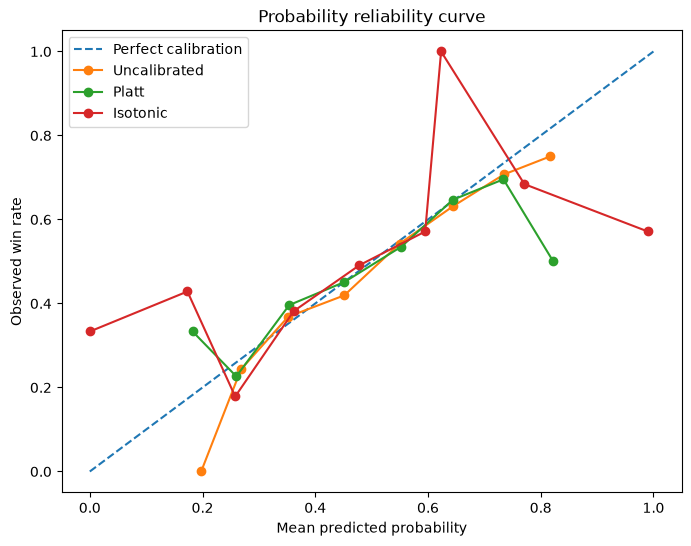

In [19]:
plt.figure(figsize=(8, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration",
)

for label, probabilities in [
    ("Uncalibrated", p_calibration_eval_raw),
    ("Platt", p_calibration_eval_platt),
    ("Isotonic", p_calibration_eval_isotonic),
]:
    table = reliability_table(
        y_calibration_eval,
        probabilities,
        n_bins=10,
    )

    valid = table["count"] > 0

    plt.plot(
        table.loc[
            valid,
            "mean_predicted_probability",
        ],
        table.loc[
            valid,
            "observed_win_rate",
        ],
        marker="o",
        label=label,
    )

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed win rate")
plt.title("Probability reliability curve")
plt.legend()
plt.show()


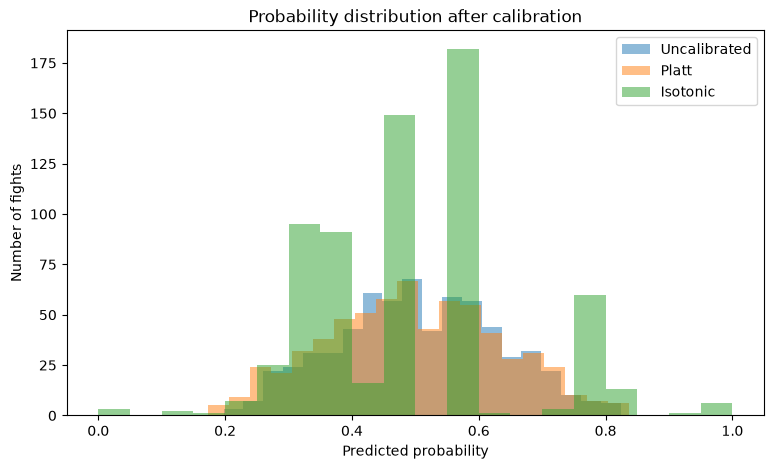

In [20]:
plt.figure(figsize=(9, 5))

plt.hist(
    p_calibration_eval_raw,
    bins=20,
    alpha=0.5,
    label="Uncalibrated",
)

plt.hist(
    p_calibration_eval_platt,
    bins=20,
    alpha=0.5,
    label="Platt",
)

plt.hist(
    p_calibration_eval_isotonic,
    bins=20,
    alpha=0.5,
    label="Isotonic",
)

plt.xlabel("Predicted probability")
plt.ylabel("Number of fights")
plt.title("Probability distribution after calibration")
plt.legend()
plt.show()


# Bootstrap the calibration improvement

A calibration method should not be selected because of a handful of fights.

I therefore bootstrap the later calibration-evaluation block and compare each calibrated method with the uncalibrated probabilities.

In [21]:
def bootstrap_logloss_delta(
    y_true: np.ndarray,
    baseline_probabilities: np.ndarray,
    candidate_probabilities: np.ndarray,
    n_bootstrap: int,
) -> dict[str, float]:
    y_true = np.asarray(y_true, dtype=int)
    baseline_probabilities = np.asarray(
        baseline_probabilities,
        dtype=float,
    )
    candidate_probabilities = np.asarray(
        candidate_probabilities,
        dtype=float,
    )

    deltas = []

    for _ in range(n_bootstrap):
        sample_idx = rng.integers(
            0,
            len(y_true),
            size=len(y_true),
        )

        baseline_ll = log_loss(
            y_true[sample_idx],
            np.clip(
                baseline_probabilities[sample_idx],
                1e-7,
                1 - 1e-7,
            ),
        )

        candidate_ll = log_loss(
            y_true[sample_idx],
            np.clip(
                candidate_probabilities[sample_idx],
                1e-7,
                1 - 1e-7,
            ),
        )

        deltas.append(
            candidate_ll - baseline_ll
        )

    deltas = np.asarray(deltas)

    return {
        "mean_delta_log_loss": float(
            deltas.mean()
        ),
        "median_delta_log_loss": float(
            np.median(deltas)
        ),
        "ci_2_5": float(
            np.quantile(deltas, 0.025)
        ),
        "ci_97_5": float(
            np.quantile(deltas, 0.975)
        ),
        "probability_improvement": float(
            (deltas < 0).mean()
        ),
    }


calibration_bootstrap_rows = []

for method, probabilities in [
    ("platt", p_calibration_eval_platt),
    ("isotonic", p_calibration_eval_isotonic),
]:
    calibration_bootstrap_rows.append({
        "method": method,
        **bootstrap_logloss_delta(
            y_calibration_eval,
            p_calibration_eval_raw,
            probabilities,
            CALIBRATION_BOOTSTRAP_SAMPLES,
        ),
    })

calibration_bootstrap_df = pd.DataFrame(
    calibration_bootstrap_rows
)

display(calibration_bootstrap_df)


,method,mean_delta_log_loss,median_delta_log_loss,ci_2_5,ci_97_5,probability_improvement
0,platt,0.000224,0.000221,-0.001933,0.002468,0.4235
1,isotonic,0.094358,0.091482,0.021652,0.185479,0.0035


# Freeze the calibration decision

I only accept a calibration method if it satisfies all of the following:

1. lower evaluation Log Loss than the uncalibrated model;
2. improvement of at least `MIN_CALIBRATION_LOGLOSS_GAIN`;
3. Brier score is not worse;
4. bootstrap probability of Log Loss improvement is at least `MIN_CALIBRATION_BOOTSTRAP_PROBABILITY`.

If neither method satisfies these requirements, I keep the CatBoost probabilities uncalibrated.

In [22]:
eligible_calibrators = []

for method in ["platt", "isotonic"]:
    result_row = calibration_results_df.loc[
        calibration_results_df["method"] == method
    ].iloc[0]

    bootstrap_row = calibration_bootstrap_df.loc[
        calibration_bootstrap_df["method"] == method
    ].iloc[0]

    logloss_gain = (
        raw_calibration_metrics["log_loss"]
        - float(result_row["log_loss"])
    )

    brier_not_worse = (
        float(result_row["brier"])
        <= raw_calibration_metrics["brier"]
    )

    bootstrap_supported = (
        float(
            bootstrap_row[
                "probability_improvement"
            ]
        )
        >= MIN_CALIBRATION_BOOTSTRAP_PROBABILITY
    )

    meaningful_gain = (
        logloss_gain
        >= MIN_CALIBRATION_LOGLOSS_GAIN
    )

    if (
        meaningful_gain
        and brier_not_worse
        and bootstrap_supported
    ):
        eligible_calibrators.append({
            "method": method,
            "log_loss": float(
                result_row["log_loss"]
            ),
            "brier": float(
                result_row["brier"]
            ),
            "logloss_gain": logloss_gain,
            "bootstrap_probability": float(
                bootstrap_row[
                    "probability_improvement"
                ]
            ),
        })

if eligible_calibrators:
    calibration_choice_df = (
        pd.DataFrame(eligible_calibrators)
        .sort_values(
            ["log_loss", "brier"]
        )
        .reset_index(drop=True)
    )

    FROZEN_CALIBRATION_METHOD = (
        calibration_choice_df.iloc[0]["method"]
    )
else:
    calibration_choice_df = pd.DataFrame()
    FROZEN_CALIBRATION_METHOD = "none"

print(
    "Frozen calibration method:",
    FROZEN_CALIBRATION_METHOD,
)

if not calibration_choice_df.empty:
    display(calibration_choice_df)
else:
    print(
        "No calibration method produced a sufficiently robust "
        "improvement. Final probabilities remain uncalibrated."
    )


Frozen calibration method: none
No calibration method produced a sufficiently robust improvement. Final probabilities remain uncalibrated.


# Save the frozen model-development configuration

The saved files are the source of truth for the final test stage.

I save:

- all fold-level hyperparameter results;
- the hyperparameter ranking;
- frozen CatBoost parameters;
- calibration metrics;
- reliability tables;
- calibration bootstrap results;
- the frozen calibration method;
- the exact feature manifest used by the final model.

In [23]:
search_results_df.to_csv(
    RESULTS_DIR / "01_hyperparameter_fold_results.csv",
    index=False,
)

search_summary_df.to_csv(
    RESULTS_DIR / "02_hyperparameter_summary.csv",
    index=False,
)

comparison.to_csv(
    RESULTS_DIR / "03_reference_vs_tuned.csv",
    index=False,
)

calibration_results_df.to_csv(
    RESULTS_DIR / "04_calibration_metrics.csv",
    index=False,
)

calibration_bootstrap_df.to_csv(
    RESULTS_DIR / "05_calibration_bootstrap.csv",
    index=False,
)

reliability_uncalibrated.to_csv(
    RESULTS_DIR / "06_reliability_uncalibrated.csv",
    index=False,
)

reliability_platt.to_csv(
    RESULTS_DIR / "07_reliability_platt.csv",
    index=False,
)

reliability_isotonic.to_csv(
    RESULTS_DIR / "08_reliability_isotonic.csv",
    index=False,
)

with (
    RESULTS_DIR / "frozen_catboost_params.json"
).open("w", encoding="utf-8") as f:
    json.dump(
        FROZEN_CATBOOST_PARAMS,
        f,
        indent=2,
        ensure_ascii=False,
    )

calibration_decision = {
    "method": FROZEN_CALIBRATION_METHOD,
    "minimum_logloss_gain_required": (
        MIN_CALIBRATION_LOGLOSS_GAIN
    ),
    "minimum_bootstrap_probability_required": (
        MIN_CALIBRATION_BOOTSTRAP_PROBABILITY
    ),
    "calibration_fit_start_index": int(search_end),
    "calibration_fit_end_index": int(
        calibration_fit_end
    ),
    "calibration_eval_start_index": int(
        calibration_fit_end
    ),
    "calibration_eval_end_index": int(
        development_end
    ),
}

with (
    RESULTS_DIR / "frozen_calibration_decision.json"
).open("w", encoding="utf-8") as f:
    json.dump(
        calibration_decision,
        f,
        indent=2,
        ensure_ascii=False,
    )

feature_manifest_snapshot = {
    "numeric_model_features": numeric_features,
    "categorical_model_features": categorical_features,
    "all_model_features": model_features,
}

with (
    RESULTS_DIR / "frozen_feature_manifest.json"
).open("w", encoding="utf-8") as f:
    json.dump(
        feature_manifest_snapshot,
        f,
        indent=2,
        ensure_ascii=False,
    )

print("Frozen artifacts saved to:")
print(RESULTS_DIR)


Frozen artifacts saved to:
c:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR\reports\final_model_optimization


# Final model-development summary

At this point I have frozen:

- the production dataset and Raw Elo system;
- the CatBoost structural hyperparameters;
- the number of boosting iterations;
- the probability-calibration policy;
- the exact model feature list.

No additional hyperparameter or calibration tuning should be performed after the final test is opened.

The next stage is the **single untouched final test evaluation**.

In [24]:
summary = {
    "best_hyperparameter_candidate": BEST_CANDIDATE_NAME,
    "frozen_iterations": FROZEN_ITERATIONS,
    "frozen_catboost_params": FROZEN_CATBOOST_PARAMS,
    "frozen_calibration_method": FROZEN_CALIBRATION_METHOD,
    "hyperparameter_mean_log_loss": float(
        BEST_SEARCH_ROW["mean_log_loss"]
    ),
    "hyperparameter_worst_log_loss": float(
        BEST_SEARCH_ROW["worst_log_loss"]
    ),
    "hyperparameter_std_log_loss": float(
        BEST_SEARCH_ROW["std_log_loss"]
    ),
    "calibration_eval_uncalibrated_log_loss": float(
        raw_calibration_metrics["log_loss"]
    ),
}

print(json.dumps(
    summary,
    indent=2,
    ensure_ascii=False,
))


{
  "best_hyperparameter_candidate": "search_33",
  "frozen_iterations": 734,
  "frozen_catboost_params": {
    "loss_function": "Logloss",
    "eval_metric": "Logloss",
    "iterations": 734,
    "depth": 4,
    "learning_rate": 0.02,
    "l2_leaf_reg": 10.0,
    "random_strength": 2.0,
    "bootstrap_type": "Bayesian",
    "bagging_temperature": 0.0,
    "border_count": 254,
    "random_seed": 42,
    "verbose": false,
    "allow_writing_files": false,
    "thread_count": -1
  },
  "frozen_calibration_method": "none",
  "hyperparameter_mean_log_loss": 0.6472345959770445,
  "hyperparameter_worst_log_loss": 0.6591564808469982,
  "hyperparameter_std_log_loss": 0.01926385610931442,
  "calibration_eval_uncalibrated_log_loss": 0.6645976895245993
}


# Optional final test — disabled

This cell is intentionally not implemented as an automatic continuation of the tuning process.

The final test should be opened only after I have reviewed the outputs above and explicitly accepted the frozen configuration.

When I do so, the evaluation must use:

- the frozen feature manifest;
- `frozen_catboost_params.json`;
- `frozen_calibration_decision.json`;
- no additional tuning after observing the test result.

The test result should then be treated as the final unbiased estimate of model performance.